CELL 1 — IMPORT LIBRAR

In [1]:
import json
import warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import Workbook, load_workbook
from google.colab import files

warnings.filterwarnings("ignore")

print("✅ Library siap.")

✅ Library siap.


CELL 2 — FUNGSI INTI SVR DAN PREPROCESSING

In [2]:
"""Kernel RBF untuk vektor — Persamaan 2.15."""
def kernel_rbf_vec(xi: np.ndarray, xj: np.ndarray, gamma: float) -> float:
    diff = xi - xj
    return float(np.exp(-gamma * np.dot(diff, diff)))

"""Prediksi jarak — Persamaan 2.16."""
def prediksi_svr_vec(x_test: np.ndarray, X_train: np.ndarray, alpha_diff: np.ndarray, b: float, gamma: float) -> float:
    kvals = np.array([kernel_rbf_vec(X_train[i], x_test, gamma) for i in range(len(X_train))])
    return float(np.dot(alpha_diff, kvals) + b)

"""Gaussian Filter — Persamaan 3.1, 3.2, 2.3, 3.3, 3.4."""
def gaussian_filter(rssi_array: np.ndarray, k: float = 1.0, q_threshold: float = 0.5) -> dict:
    n = len(rssi_array)
    k_used = k

    while True:
        xe = np.mean(rssi_array)
        omega = np.sqrt(np.mean((rssi_array - xe) ** 2))
        mask = np.abs(rssi_array - xe) < k_used * omega
        data_bersih = rssi_array[mask]
        P = (len(data_bersih) / n) * 100

        if P >= q_threshold * 100 or k_used >= 3:
            break
        k_used += 1

    xe_bersih = np.mean(data_bersih)
    return {"xe_bersih": xe_bersih, "data_bersih": data_bersih}

"""Kalman Filter — Persamaan 2.4 s/d 2.9. Return xk_final."""
def kalman_filter(rssi_array: np.ndarray, phi: float = 1.0, Q: float = 0.01,
                  Rv: float = 0.1, P0: float = 1.0) -> float:
    x_est, P_est = rssi_array[0], P0

    for zk in rssi_array:
        x_pred = phi * x_est
        P_pred = (phi * P_est * phi) + Q
        Kk = P_pred / (P_pred + Rv)
        x_est = x_pred + Kk * (zk - x_pred)
        P_est = (1 - Kk) * P_pred

    return float(x_est)

"""Pipeline Gaussian → Kalman, return satu nilai xk_final."""
def preprocessing(rssi_array: np.ndarray) -> float:
    hasil_gaussian = gaussian_filter(rssi_array)
    return kalman_filter(hasil_gaussian["data_bersih"])

print("✅ Fungsi SVR dan preprocessing siap.")

✅ Fungsi SVR dan preprocessing siap.


CELL 3 — UPLOAD FILE MODEL DAN DATA PENGUJIAN

In [10]:
"""
Upload :
   1. model_svr_landmarc_*.json
   2. File data tag target untuk PENGUJIAN
      Contoh nama file:
      - data_Skenario1_LOS_Target_90cm_*.xlsx
      - data_Skenario2_LOS_Target_90cm_*.xlsx
"""
print("Upload file berikut sekaligus:")
print("  1. model_svr_landmarc_*.json")
print("  2. File Excel data tag target pengujian")
print("     Skenario 1: sheet Target + R1 + R2")
print("     Skenario 2: sheet Target + R1 + R2 + R3")
print()

uploaded = files.upload()
filenames = list(uploaded.keys())

model_files = [f for f in filenames if f.endswith(".json")]
target_files = [f for f in filenames if f.endswith(".xlsx") and "_Target_" in f]

print(f"\n✅ File model  : {model_files}")
print(f"✅ File target : {target_files}")

Upload file berikut sekaligus:
  1. model_svr_landmarc_*.json
  2. File Excel data tag target pengujian
     Skenario 1: sheet Target + R1 + R2
     Skenario 2: sheet Target + R1 + R2 + R3



Saving data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx to data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx
Saving data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx to data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx
Saving model_svr_landmarc_20260930_170856.json to model_svr_landmarc_20260930_170856.json

✅ File model  : ['model_svr_landmarc_20260930_170856.json']
✅ File target : ['data_Skenario2_LOS_Target_90cm_20260511_131200.xlsx', 'data_Skenario2_LOS_Target_110cm_20260511_131954.xlsx']


CELL 4 — LOAD MODEL

In [11]:
def load_model(json_file: str) -> dict:
    with open(json_file, "r") as f:
        raw = json.load(f)

    models = {}
    for nama, p in raw.items():
        models[nama] = {
            "gamma": p["gamma"],
            "C": p["C"],
            "epsilon": p["epsilon"],
            "b": p["b"],
            "alpha_diff": np.array(p["alpha_diff"]),
            "X_train": np.array(p["X_train"]),
            "y_train": np.array(p["y_train"]),
            "urutan_ref": p["urutan_ref"],
            "kondisi": p["kondisi"],
            "n_fitur": p["n_fitur"],
            "jarak_training_cm": p.get("jarak_training_cm", []),
            "jarak_ref_per_tag": p.get("jarak_ref_m", {}),
        }

    return models


semua_model = {}
for mf in model_files:
    semua_model.update(load_model(mf))

print("✅ Model dimuat:")
for nama, model in semua_model.items():
    refs = "+".join(model["urutan_ref"]) + "+Target"
    print(f"\n  📋 {nama}")
    print(f"  ├─ γ={model['gamma']}, C={model['C']}, ε={model['epsilon']}")
    print(f"  ├─ b = {model['b']:.6f}")
    print(f"  ├─ Input = {model['n_fitur']}D [{refs}]")
    print(f"  ├─ Training = {model['jarak_training_cm']} cm")
    print(f"  └─ Referensi = {model['jarak_ref_per_tag']}")

✅ Model dimuat:

  📋 Skenario2
  ├─ γ=0.01, C=10, ε=0.001
  ├─ b = 1.304405
  ├─ Input = 4D [R1+R2+R3+Target]
  ├─ Training = [80, 100, 140, 170] cm
  └─ Referensi = {'R1': 0.5, 'R2': 1.25, 'R3': 2.0}


CELL 5 — PREPROCESSING DATA PENGUJIAN

In [12]:
"""
    Baca file Excel data pengujian:

    Setiap file sheet skenario 1: Target, R1, R2
    Buat vektor input [xk_R1, xk_R2, xk_Target] untuk prediksi.

    Setiap file sheet skenario 2: Target, R1, R2, R3
    Buat vektor input [xk_R1, xk_R2, xk_R3, xk_Target] untuk prediksi.
"""
def baca_data_pengujian(filelist: list, urutan_ref: list) -> list:
    hasil = []

    for fname in filelist:
        wb = load_workbook(fname)
        data_per_sheet = {}

        for sheet_name in wb.sheetnames:
            if sheet_name.lower() == "ringkasan":
                continue

            rows = list(wb[sheet_name].iter_rows(values_only=True))
            if len(rows) < 2:
                continue

            df = pd.DataFrame(rows[1:], columns=rows[0])
            df["RSSI (dBm)"] = pd.to_numeric(df["RSSI (dBm)"], errors="coerce")
            df = df.dropna(subset=["RSSI (dBm)"])
            data_per_sheet[sheet_name] = df

        if "Target" not in data_per_sheet:
            print(f"  ⚠️ Sheet 'Target' tidak ada di {fname}")
            continue

        df_target = data_per_sheet["Target"]
        jarak_aktual = float(df_target["Jarak Aktual (cm)"].iloc[0]) / 100.0
        kondisi = str(df_target["Kondisi"].iloc[0]) if "Kondisi" in df_target.columns else "LOS"
        skenario = str(df_target["Skenario"].iloc[0]) if "Skenario" in df_target.columns else ""

        xk_target = preprocessing(df_target["RSSI (dBm)"].values)

        xk_refs = {}
        for ref_name in urutan_ref:
            if ref_name in data_per_sheet:
                xk_refs[ref_name] = preprocessing(data_per_sheet[ref_name]["RSSI (dBm)"].values)
            else:
                print(f"  ⚠️ Sheet '{ref_name}' tidak ada di {fname}")
                xk_refs[ref_name] = 0.0

        vektor = [xk_refs[ref] for ref in urutan_ref] + [xk_target]

        hasil.append({
            "jarak_aktual_m": jarak_aktual,
            "xk_target": xk_target,
            "xk_refs": xk_refs,
            "vektor_input": np.array(vektor),
            "kondisi": kondisi,
            "skenario": skenario,
            "filename": fname,
        })

    hasil.sort(key=lambda x: x["jarak_aktual_m"])
    return hasil


print("=" * 60)
print("  PREPROCESSING DATA PENGUJIAN")
print("=" * 60)

nama_skenario = list(semua_model.keys())[0]
urutan_ref = semua_model[nama_skenario]["urutan_ref"]

data_uji = baca_data_pengujian(target_files, urutan_ref)

header_ref = "  ".join(f"{'xk_' + ref:>10}" for ref in urutan_ref)
print(f"\n  {'Jarak':>8}  {'xk_Target':>12}  {header_ref}")
print(f"  {'-' * 8}  {'-' * 12}  " + "  ".join(["-" * 10] * len(urutan_ref)))

for data in data_uji:
    refs_str = "  ".join(f"{data['xk_refs'].get(ref, 0):>10.5f}" for ref in urutan_ref)
    print(f"  {data['jarak_aktual_m'] * 100:>6.0f}cm  {data['xk_target']:>12.5f}  {refs_str}")

print(f"\n✅ {len(data_uji)} file pengujian dipreprocessing.")

  PREPROCESSING DATA PENGUJIAN

     Jarak     xk_Target       xk_R1       xk_R2       xk_R3
  --------  ------------  ----------  ----------  ----------
      90cm     -50.00000   -43.00000   -52.00000   -61.00000
     110cm     -52.00000   -42.00000   -52.00000   -61.00000

✅ 2 file pengujian dipreprocessing.


CELL 6 — PENGUJIAN MODEL

In [13]:
def pembulatan_cm(nilai_m: float) -> int:
    return int(np.floor(nilai_m * 100 + 0.5))


hasil_pengujian = {}

print("=" * 60)
print("  PENGUJIAN MODEL SVR-LANDMARC")
print("=" * 60)

for nama_skenario, model in semua_model.items():
    print(f"\n📋 {nama_skenario} — {model['kondisi']}:")
    print(f"  {'Jarak Aktual':>13} {'Vektor Input':>35} {'Prediksi':>10} {'Error':>10}")
    print(f"  {'-' * 13} {'-' * 35} {'-' * 10} {'-' * 10}")

    hasil_per_target = []

    for data in data_uji:
        jarak_pred_m = prediksi_svr_vec(
            data["vektor_input"], model["X_train"],
            model["alpha_diff"], model["b"], model["gamma"]
        )

        jarak_aktual_cm = pembulatan_cm(data["jarak_aktual_m"])
        jarak_prediksi_cm = pembulatan_cm(jarak_pred_m)
        error_cm = abs(jarak_aktual_cm - jarak_prediksi_cm)
        vec_str = str(np.round(data["vektor_input"], 2).tolist())

        print(
            f"  {jarak_aktual_cm:>11}cm  {vec_str:>35}  "
            f"{jarak_prediksi_cm:>8}cm  {error_cm:>8}cm"
        )

        hasil_per_target.append({
            "jarak_aktual_m": jarak_aktual_cm / 100.0,
            "jarak_aktual_cm": jarak_aktual_cm,
            "vektor_input": data["vektor_input"],
            "jarak_prediksi_m_raw": jarak_pred_m,
            "jarak_prediksi_cm_raw": jarak_pred_m * 100,
            "jarak_prediksi_m": jarak_prediksi_cm / 100.0,
            "jarak_prediksi_cm": jarak_prediksi_cm,
            "error_m": error_cm / 100.0,
            "error_cm": error_cm,
        })

    y_act_cm = np.array([r["jarak_aktual_cm"] for r in hasil_per_target], dtype=float)
    y_pred_cm = np.array([r["jarak_prediksi_cm"] for r in hasil_per_target], dtype=float)
    error_cm_arr = np.abs(y_pred_cm - y_act_cm)

    mae_cm = float(np.mean(error_cm_arr))
    rmse_cm = float(np.sqrt(np.mean(error_cm_arr ** 2)))

    hasil_pengujian[nama_skenario] = {
        "hasil_per_target": hasil_per_target,
        "mae_m": mae_cm / 100.0,
        "mae_cm": mae_cm,
        "rmse_m": rmse_cm / 100.0,
        "rmse_cm": rmse_cm,
    }

    print(f"\n  ┌─────────────────────────────┐")
    print(f"  │  MAE  = {mae_cm:>8.2f} cm         │")
    print(f"  │  RMSE = {rmse_cm:>8.2f} cm         │")
    print(f"  └─────────────────────────────┘")

print("\n✅ Pengujian selesai.")

  PENGUJIAN MODEL SVR-LANDMARC

📋 Skenario2 — LOS:
   Jarak Aktual                        Vektor Input   Prediksi      Error
  ------------- ----------------------------------- ---------- ----------
           90cm         [-43.0, -52.0, -61.0, -50.0]        93cm         3cm
          110cm         [-42.0, -52.0, -61.0, -52.0]       105cm         5cm

  ┌─────────────────────────────┐
  │  MAE  =     4.00 cm         │
  │  RMSE =     4.12 cm         │
  └─────────────────────────────┘

✅ Pengujian selesai.


CELL 7 — VISUALISASI

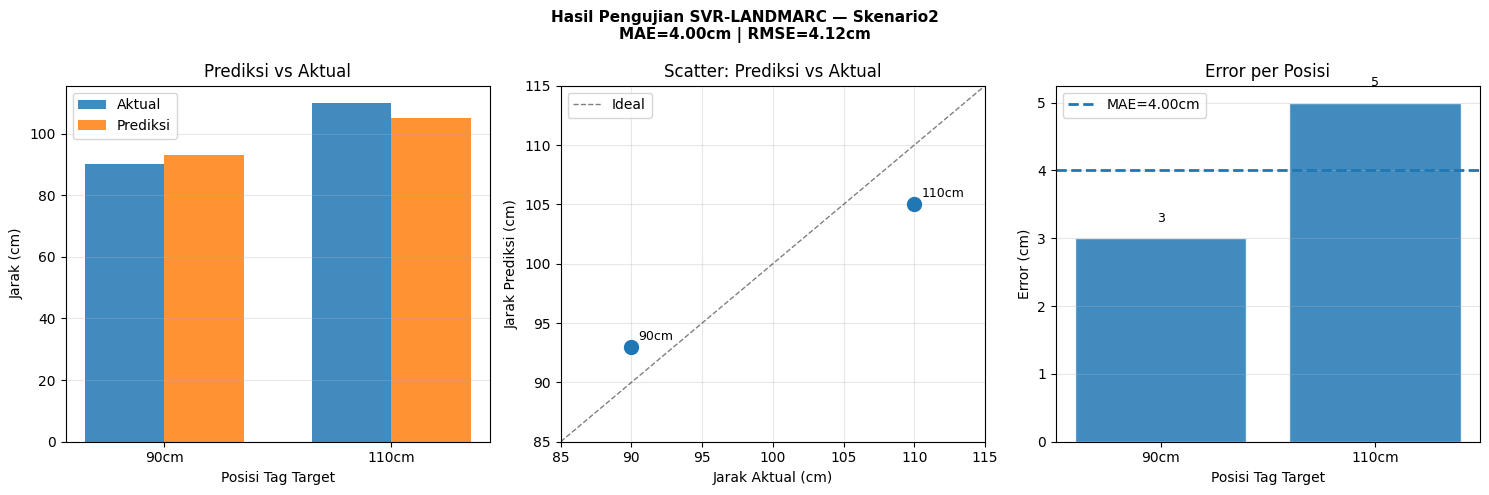

✅ Plot disimpan: pengujian_Skenario2.png


In [14]:
for nama_skenario, hasil in hasil_pengujian.items():
    records = hasil["hasil_per_target"]
    y_act = np.array([r["jarak_aktual_cm"] for r in records])
    y_pred = np.array([r["jarak_prediksi_cm"] for r in records])
    errors = np.array([r["error_cm"] for r in records])

    x_labels = [f"{int(r['jarak_aktual_cm'])}cm" for r in records]
    x_pos = np.arange(len(records))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(
        f"Hasil Pengujian SVR-LANDMARC — {nama_skenario}\n"
        f"MAE={hasil['mae_cm']:.2f}cm | RMSE={hasil['rmse_cm']:.2f}cm",
        fontsize=11, fontweight="bold"
    )

    # Panel 1 — Prediksi vs Aktual
    ax1 = axes[0]
    width = 0.35
    ax1.bar(x_pos - width / 2, y_act, width, label="Aktual", alpha=0.85)
    ax1.bar(x_pos + width / 2, y_pred, width, label="Prediksi", alpha=0.85)
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels)
    ax1.set_xlabel("Posisi Tag Target")
    ax1.set_ylabel("Jarak (cm)")
    ax1.set_title("Prediksi vs Aktual")
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis="y")

    # Panel 2 — Scatter
    ax2 = axes[1]
    lim = [min(y_act.min(), y_pred.min()) - 5, max(y_act.max(), y_pred.max()) + 5]
    ax2.plot(lim, lim, "k--", lw=1, alpha=0.5, label="Ideal")
    ax2.scatter(y_act, y_pred, s=100, zorder=5)

    for i, label in enumerate(x_labels):
        ax2.annotate(label, xy=(y_act[i], y_pred[i]), xytext=(5, 5),
                     textcoords="offset points", fontsize=9)

    ax2.set_xlabel("Jarak Aktual (cm)")
    ax2.set_ylabel("Jarak Prediksi (cm)")
    ax2.set_title("Scatter: Prediksi vs Aktual")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(lim)
    ax2.set_ylim(lim)

    # Panel 3 — Error per Posisi
    ax3 = axes[2]
    bars = ax3.bar(x_labels, errors, alpha=0.85, edgecolor="white")
    ax3.axhline(
        hasil["mae_cm"], lw=2, ls="--",
        label=f"MAE={hasil['mae_cm']:.2f}cm"
    )

    for bar, value in zip(bars, errors):
        ax3.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f"{int(value)}",
            ha="center", va="bottom", fontsize=9
        )

    ax3.set_xlabel("Posisi Tag Target")
    ax3.set_ylabel("Error (cm)")
    ax3.set_title("Error per Posisi")
    ax3.legend()
    ax3.grid(True, alpha=0.3, axis="y")

    plt.tight_layout()

    fname_plot = f"pengujian_{nama_skenario}.png"
    plt.savefig(fname_plot, dpi=120, bbox_inches="tight")
    plt.show()

    print(f"✅ Plot disimpan: {fname_plot}")

CELL 8 — SIMPAN HASIL DAN DOWNLOAD

In [15]:
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"hasil_pengujian_{ts}.xlsx"

wb = Workbook()
wb.remove(wb.active)

# Sheet Ringkasan
ws_sum = wb.create_sheet(title="Ringkasan", index=0)
ws_sum.append([
    "Skenario", "Kondisi", "Jumlah Target",
    "MAE (cm)", "RMSE (cm)", "MAE (m)", "RMSE (m)"
])

for nama_skenario, hasil in hasil_pengujian.items():
    kondisi = semua_model[nama_skenario]["kondisi"]

    ws_sum.append([
        nama_skenario, kondisi, len(hasil["hasil_per_target"]),
        round(hasil["mae_cm"], 2), round(hasil["rmse_cm"], 2),
        round(hasil["mae_m"], 4), round(hasil["rmse_m"], 4)
    ])

    # Sheet Detail
    ws = wb.create_sheet(title=f"{nama_skenario}_Detail")
    ws.append([
        "No", "Jarak Aktual (cm)", "Vektor Input",
        "Jarak Prediksi (cm)", "Error (cm)", "Kondisi", "Skenario"
    ])

    for i, record in enumerate(hasil["hasil_per_target"], 1):
        vec_str = str(np.round(record["vektor_input"], 4).tolist())
        ws.append([
            i, int(record["jarak_aktual_cm"]), vec_str,
            int(record["jarak_prediksi_cm"]), int(record["error_cm"]),
            kondisi, nama_skenario
        ])

    ws.append([])
    ws.append(["", "MAE (cm)", round(hasil["mae_cm"], 2)])
    ws.append(["", "RMSE (cm)", round(hasil["rmse_cm"], 2)])

# Atur lebar kolom
for ws in wb.worksheets:
    for col in ws.columns:
        width = max((len(str(cell.value or "")) for cell in col), default=0)
        ws.column_dimensions[col[0].column_letter].width = min(width + 4, 35)

wb.save(filename)
files.download(filename)

print(f"✅ Hasil disimpan dan didownload: {filename}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Hasil disimpan dan didownload: hasil_pengujian_20260930_171815.xlsx


CELL 9 — RINGKASAN AKHIR

In [16]:
print("\n" + "=" * 60)
print("  RINGKASAN HASIL PENGUJIAN SVR-LANDMARC")
print("=" * 60)

for nama_skenario, hasil in hasil_pengujian.items():
    kondisi = semua_model[nama_skenario]["kondisi"]

    print(f"\n📋 {nama_skenario} — {kondisi}:")
    print(f"  {'Posisi':>8} {'Aktual':>10} {'Prediksi':>11} {'Error':>10}")
    print(f"  {'-' * 8} {'-' * 10} {'-' * 11} {'-' * 10}")

    for record in hasil["hasil_per_target"]:
        print(
            f"  {record['jarak_aktual_cm']:>6}cm  "
            f"{record['jarak_aktual_cm']:>8}cm  "
            f"{record['jarak_prediksi_cm']:>9}cm  "
            f"{record['error_cm']:>8}cm"
        )

    print(f"\n  MAE  = {hasil['mae_cm']:.2f} cm")
    print(f"  RMSE = {hasil['rmse_cm']:.2f} cm")

print("\n" + "=" * 60)
print("  ✅ Pengujian selesai!")
print("=" * 60)


  RINGKASAN HASIL PENGUJIAN SVR-LANDMARC

📋 Skenario2 — LOS:
    Posisi     Aktual    Prediksi      Error
  -------- ---------- ----------- ----------
      90cm        90cm         93cm         3cm
     110cm       110cm        105cm         5cm

  MAE  = 4.00 cm
  RMSE = 4.12 cm

  ✅ Pengujian selesai!
